   survived  pclass     sex   age  sibsp  parch     fare embarked  class  \
0         0       3    male  22.0      1      0   7.2500        S  Third   
1         1       1  female  38.0      1      0  71.2833        C  First   
2         1       3  female  26.0      0      0   7.9250        S  Third   
3         1       1  female  35.0      1      0  53.1000        S  First   
4         0       3    male  35.0      0      0   8.0500        S  Third   

     who  adult_male deck  embark_town alive  alone  
0    man        True  NaN  Southampton    no  False  
1  woman       False    C    Cherbourg   yes  False  
2  woman       False  NaN  Southampton   yes   True  
3  woman       False    C  Southampton   yes  False  
4    man        True  NaN  Southampton    no   True  
Shape: (891, 15)
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 

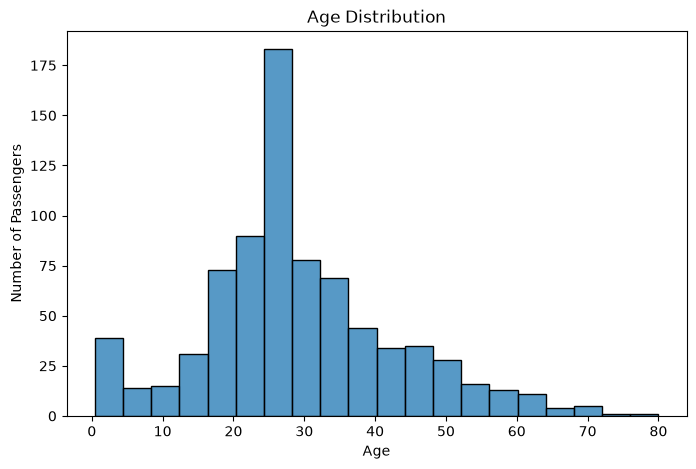

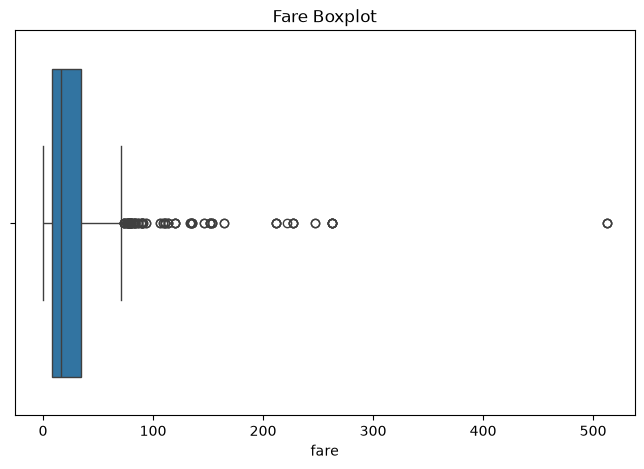

Input Shape: (784, 7)
Output Shape: (784,)
Training Data: (627, 7)
Testing Data: (157, 7)
Encoding completed
       age  sibsp  parch      fare  sex_female  sex_male  embarked_C  \
869   4.00      1      1   11.1333           0         1           0   
37   21.00      0      0    8.0500           0         1           0   
380  42.00      0      0  227.5250           1         0           1   
825  28.25      0      0    6.9500           0         1           0   
199  24.00      0      0   13.0000           1         0           0   

     embarked_Q  embarked_S  pclass_1  pclass_2  pclass_3  
869           0           1         0         0         1  
37            0           1         0         0         1  
380           0           0         1         0         0  
825           1           0         0         0         1  
199           0           1         0         1         0  
Feature scaling completed
Training Data: (627, 12)
Testing Data: (157, 12)

Missing Values:
age   

In [1]:
# Step 1: Import required libraries

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler


# Step 2: Load Titanic dataset

df = sns.load_dataset("titanic")

# Display first 5 rows
print(df.head())

# Display number of rows and columns
print("Shape:", df.shape)


# Step 3: Explore dataset

# Display column names, data types and non-null values
df.info()

# Display all column names
print(df.columns.tolist())

# Display missing values in each column
print(df.isnull().sum())


# Step 4: Data Cleaning

# Count duplicate rows
print("Duplicates:", df.duplicated().sum())

# Remove duplicate rows
df = df.drop_duplicates()

print("Shape after cleaning:", df.shape)


# Step 5: Missing Value Handling

# Fill missing age values with median age
df['age'] = df['age'].fillna(df['age'].median())

# Fill missing fare values with median fare
df['fare'] = df['fare'].fillna(df['fare'].median())

# Fill missing embarked values with most frequent value (mode)
df['embarked'] = df['embarked'].fillna(df['embarked'].mode()[0])

# Check missing values after handling
print(df[['age', 'fare', 'embarked']].isnull().sum())


# Step 6: Statistical Analysis

# Display count, mean, standard deviation, minimum, maximum, etc.
print(df[['age', 'fare', 'sibsp', 'parch']].describe())

# Count survived and non-survived passengers
print(df['survived'].value_counts())

# Calculate average age and fare
print("Average Age:", df['age'].mean())
print("Average Fare:", df['fare'].mean())


# Step 7: Histogram

# Create histogram to understand age distribution
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x='age', bins=20)

plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Number of Passengers")
plt.show()


# Step 8: Boxplot

# Create boxplot to identify potential outliers in fare
plt.figure(figsize=(8, 5))
sns.boxplot(x=df['fare'])

plt.title("Fare Boxplot")
plt.show()


# Step 9: Separate Input and Output

# X contains passenger information (input features)
X = df[['pclass', 'sex', 'age', 'sibsp',
        'parch', 'fare', 'embarked']]

# y contains survival result (target/output)
y = df['survived']

print("Input Shape:", X.shape)
print("Output Shape:", y.shape)


# Step 10: Train-Test Split

# Divide dataset into 80% training and 20% testing
# random_state ensures the same split every time
# stratify maintains the survival class proportions
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)


# Step 11: Encoding

# Convert categorical text columns into numerical columns
# One-Hot Encoding creates separate 0/1 columns
X_train = pd.get_dummies(
    X_train,
    columns=['sex', 'embarked', 'pclass'],
    dtype=int
)

X_test = pd.get_dummies(
    X_test,
    columns=['sex', 'embarked', 'pclass'],
    dtype=int
)

# Ensure training and testing have identical columns
X_test = X_test.reindex(
    columns=X_train.columns,
    fill_value=0
)

print("Encoding completed")
print(X_train.head())


# Step 12: Feature Scaling

# Create StandardScaler object
scaler = StandardScaler()

# Select numerical columns for scaling
cols = ['age', 'sibsp', 'parch', 'fare']

# Learn scaling parameters from training data and transform it
X_train[cols] = scaler.fit_transform(X_train[cols])

# Apply the same scaling parameters to testing data
X_test[cols] = scaler.transform(X_test[cols])

print("Feature scaling completed")


# Step 13: Final Output

# Display final training and testing shapes
print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

# Check whether any missing values remain
print("\nMissing Values:")
print(X_train.isnull().sum())

print("\nPreprocessing Completed Successfully!")